<a href="https://colab.research.google.com/github/Saumyam246/Machine-Learning-Final-Project/blob/main/ML_Flow_HNSCC.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [69]:

import os
import pandas as pd

# Find Clinical Dataset
CLIN = next(
    (
        os.path.join(folder, "HNSCC_sequential_clinical_long.csv")
        for folder in ["/content", "/"]
        if os.path.exists(
            os.path.join(folder, "HNSCC_sequential_clinical_long.csv")
        )
    ),
    None
)

# Find Image Dataset
IMG = next(
    (
        os.path.join(folder, "unsupervised_image_features.csv")
        for folder in ["/content", "/"]
        if os.path.exists(
            os.path.join(folder, "unsupervised_image_features.csv")
        )
    ),
    None
)

# Check dataset files
if CLIN is None:
    raise FileNotFoundError("Clinical dataset not found!")

if IMG is None:
    raise FileNotFoundError("Image dataset not found!")

# Load datasets
df = pd.read_csv(CLIN)
img_df = pd.read_csv(IMG)

# Display results
print("Clinical dataset loaded successfully!")
print("Clinical data:", df.shape)

print("\nImage dataset loaded successfully!")
print("Image data:", img_df.shape)

print("\nClinical Dataset Preview:")
display(df.head())

print("\nImage Dataset Preview:")
display(img_df.head())


Clinical dataset loaded successfully!
Clinical data: (93, 15)

Image dataset loaded successfully!
Image data: (237, 97)

Clinical Dataset Preview:


,HN_P,stage,time_days_relative_to_treatment,weight_lbs,age,sex,cancer_staging,tumor_location,performance_status,chemotherapy_medication,ptv_volume_cm3,total_dose_gy,number_of_fractions,dose_per_fraction_gy,outcome_text
0,1,Pre-Tx,-14,138,64,M,IVA,Left base of the tongue and retromolar trigone,ECOG 0-1,"Cisplatin, Cetuximab",93.50,69.96,33,2.12,Baseline; no corresponding baseline outcome field
1,1,Mid-Tx,33,138,64,M,IVA,Left base of the tongue and retromolar trigone,ECOG 0-1,"Cisplatin, Cetuximab",93.50,69.96,33,2.12,"Grade 2 xerostomia, Grade 3 mucositis."
2,1,Post-Tx,47,131,64,M,IVA,Left base of the tongue and retromolar trigone,ECOG 0-1,"Cisplatin, Cetuximab",93.50,69.96,33,2.12,"No palpable adenopathy of the head, neck or su..."
3,2,Pre-Tx,-12,164,83,M,IVA,Right tonsil with cervical adenopathy,ECOG 0-1,"Carboplatin, Cetuximab",252.97,69.96,33,2.12,Baseline; no corresponding baseline outcome field
4,2,Mid-Tx,21,164,83,M,IVA,Right tonsil with cervical adenopathy,ECOG 0-1,"Carboplatin, Cetuximab",252.97,69.96,33,2.12,"Grade 2 mucositis involving the soft palate, G..."



Image Dataset Preview:


,image_name,R_1,R_2,R_3,R_4,R_5,R_6,R_7,R_8,R_9,...,B_23,B_24,B_25,B_26,B_27,B_28,B_29,B_30,B_31,B_32
0,0000.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.055288,0.117500,0.193871,0.193008,0.166154,0.099966,0.054019,0.033749,0.018000,0.029366
1,0001.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000002,0.000094,0.000471,...,0.042778,0.081940,0.123359,0.145769,0.203150,0.168397,0.084192,0.047719,0.024065,0.034847
2,0002.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.145619,0.182409,0.160474,0.105413,0.076530,0.045042,0.022069,0.012282,0.005563,0.003574
3,0003.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000015,0.000330,0.001024,...,0.104403,0.151777,0.165196,0.135668,0.120815,0.078147,0.038009,0.021031,0.009901,0.012621
4,0004.png,0.0,0.0,0.0,0.0,0.0,0.0,0.000000,0.000000,0.000000,...,0.085838,0.165844,0.225083,0.180063,0.136934,0.070963,0.031084,0.015942,0.006724,0.003929


## Step 1 – Preprocessing (clinical data)
- Long format (3 rows per patient) → one row per patient.
- Baseline features (age, sex, stage, tumour volume, dose, chemo, tumour site) are constant per patient.
- `performance_status` and `chemotherapy_medication` have missing values → imputed inside the pipeline.
- Messy text (`tumor_location`, drug names) → grouped into clean categories.

In [11]:
order = ['Pre-Tx','Mid-Tx','Post-Tx']
W = df.pivot(index='HN_P', columns='stage', values='weight_lbs')[order]
base = df[df.stage=='Pre-Tx'].set_index('HN_P')

def site(t):
    t = str(t).lower()
    if 'tonsil' in t: return 'tonsil'
    if 'base of' in t or 'base of the tongue' in t: return 'base_of_tongue'
    if 'tongue' in t: return 'oral_tongue'
    if 'floor' in t or 'retromolar' in t or 'buccal' in t or 'gingiva' in t: return 'oral_cavity_other'
    return 'other'
def chemo(c):
    c = str(c).lower()
    if c == 'nan': return 'unknown'
    if 'carbo' in c: return 'carboplatin'
    if 'cis' in c: return 'cisplatin'
    return 'cetuximab_only'

P = pd.DataFrame(index=W.index)
P['age'] = base.age; P['sex'] = base.sex
P['stage_grp'] = base.cancer_staging.map(lambda s: 'early(I-II)' if s in ['I','II','IIA','IIB'] else s)
P['ptv_volume'] = base.ptv_volume_cm3; P['dose'] = base.total_dose_gy
P['fractions'] = base.number_of_fractions
P['site'] = base.tumor_location.map(site)
P['chemo'] = base.chemotherapy_medication.map(chemo)
P['baseline_weight'] = W['Pre-Tx']
P['post_pct_change'] = (W['Post-Tx']/W['Pre-Tx']-1)*100
# TARGET: clinically meaningful weight loss >=5% by end of treatment (malnutrition risk)
P['target'] = (P.post_pct_change <= -5).astype(int)
print(P.target.value_counts().to_dict(), '(1 = >=5% weight loss)')
P.head()

{0: 17, 1: 14} (1 = >=5% weight loss)


,age,sex,stage_grp,ptv_volume,dose,fractions,site,chemo,baseline_weight,post_pct_change,target
HN_P,,,,,,,,,,,
1,64,M,IVA,93.50,69.96,33,base_of_tongue,cisplatin,138,-5.072464,1
2,83,M,IVA,252.97,69.96,33,tonsil,carboplatin,164,-4.268293,0
3,87,M,IVA,133.77,69.96,33,base_of_tongue,carboplatin,210,-7.142857,1
4,66,M,IVA,260.89,70.00,35,base_of_tongue,cetuximab_only,201,-3.482587,0
5,55,M,IVA,34.10,70.00,35,base_of_tongue,cisplatin,187,-3.208556,0


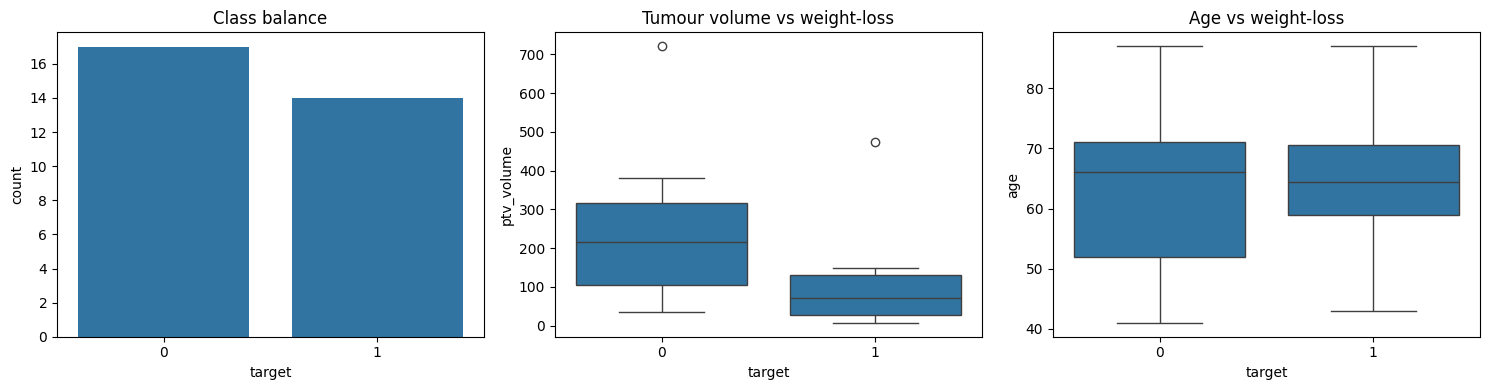

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

#Quick EDA
fig, ax = plt.subplots(1,3, figsize=(15,4))
sns.countplot(x='target', data=P, ax=ax[0]); ax[0].set_title('Class balance')
sns.boxplot(x='target', y='ptv_volume', data=P, ax=ax[1]); ax[1].set_title('Tumour volume vs weight-loss')
sns.boxplot(x='target', y='age', data=P, ax=ax[2]); ax[2].set_title('Age vs weight-loss')
plt.tight_layout(); plt.show()

# UNIT 4 – HIDDEN MARKOV MODELS
**Idea:** each patient is a *sequence* Pre-Tx → Mid-Tx → Post-Tx. We cannot directly see the patient's true nutritional/toxicity state (**hidden**), only the weight change we observe (**observation**).

| Syllabus topic | Where in code |
|---|---|
| Sequential data / Markov model | transition matrix A |
| HMM | (π, A, B) |
| Forward / backward algorithm | `forward()`, `backward()` |
| Scaling factors | scaling `c_t` inside forward |
| Maximum likelihood for HMM | Baum-Welch (EM) `baum_welch()` |
| Viterbi | `viterbi()` |

**Observations** (weight vs. baseline at each stage): 0 = stable (> -2%), 1 = mild loss (-2% to -5%), 2 = marked loss (< -5%)
**Hidden states:** 2 states, learned automatically (we interpret them afterwards as "stable" vs "deteriorating").

In [15]:
import numpy as np

rel = W.div(W['Pre-Tx'], axis=0).sub(1).mul(100)         # % change vs baseline at every stage
def to_sym(x): return 0 if x > -2 else (1 if x > -5 else 2)
OBS = [[to_sym(v) for v in rel.loc[p, order]] for p in rel.index]
print('Example sequences (patient 1..5):', OBS[:5])
print('Symbol counts:', np.bincount(np.array(OBS).ravel(), minlength=3))

Example sequences (patient 1..5): [[0, 0, 2], [0, 0, 1], [0, 0, 2], [0, 0, 1], [0, 0, 1]]
Symbol counts: [70  9 14]


Initial pi: [1. 0.]
Transition A:
 [[0.41 0.59]
 [0.   1.  ]]
Emission B:
 [[1.   0.   0.  ]
 [0.47 0.21 0.33]]


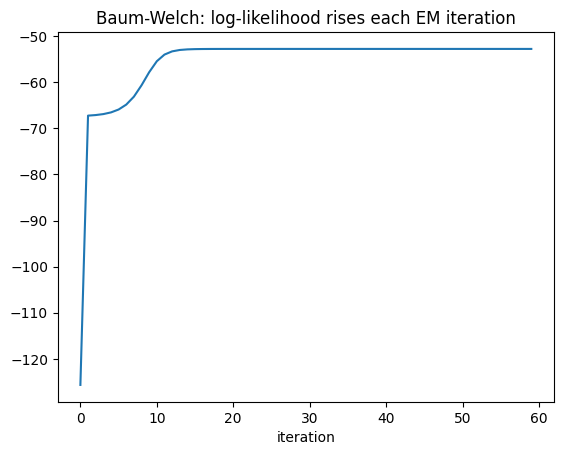

In [16]:
# ---------- HMM from scratch with scaling (numerically stable) ----------
def forward(obs, pi, A, B):
    T, N = len(obs), len(pi)
    alpha = np.zeros((T,N)); c = np.zeros(T)
    alpha[0] = pi*B[:,obs[0]]; c[0] = alpha[0].sum(); alpha[0] /= c[0]
    for t in range(1,T):
        alpha[t] = (alpha[t-1] @ A) * B[:,obs[t]]
        c[t] = alpha[t].sum(); alpha[t] /= c[t]          # scaling factor
    return alpha, c                                       # log-likelihood = sum(log c)

def backward(obs, A, B, c):
    T, N = len(obs), A.shape[0]
    beta = np.zeros((T,N)); beta[-1] = 1
    for t in range(T-2,-1,-1):
        beta[t] = (A @ (B[:,obs[t+1]]*beta[t+1])) / c[t+1]
    return beta

def viterbi(obs, pi, A, B):
    T, N = len(obs), len(pi)
    d = np.zeros((T,N)); psi = np.zeros((T,N), int)
    d[0] = np.log(pi+1e-12) + np.log(B[:,obs[0]]+1e-12)
    for t in range(1,T):
        s = d[t-1][:,None] + np.log(A+1e-12)
        psi[t] = s.argmax(0); d[t] = s.max(0) + np.log(B[:,obs[t]]+1e-12)
    path = [d[-1].argmax()]
    for t in range(T-1,0,-1): path.append(psi[t][path[-1]])
    return path[::-1]

def baum_welch(seqs, N=2, M=3, iters=60, seed=0):
    rng = np.random.default_rng(seed)
    pi = rng.dirichlet(np.ones(N)); A = rng.dirichlet(np.ones(N), N); B = rng.dirichlet(np.ones(M), N)
    ll_hist = []
    for _ in range(iters):
        pi_n = np.zeros(N); A_n = np.zeros((N,N)); B_n = np.zeros((N,M)); g_tot = np.zeros(N); ll = 0
        for o in seqs:
            al, c = forward(o, pi, A, B); be = backward(o, A, B, c); ll += np.log(c).sum()
            gamma = al*be
            gamma /= gamma.sum(1, keepdims=True)
            pi_n += gamma[0]
            for t in range(len(o)-1):
                xi = al[t][:,None]*A*(B[:,o[t+1]]*be[t+1])[None,:]
                A_n += xi/xi.sum()
            for t,ot in enumerate(o): B_n[:,ot] += gamma[t]
        pi = pi_n/pi_n.sum()
        A  = A_n/A_n.sum(1,keepdims=True)
        B  = (B_n+1e-6)/(B_n+1e-6).sum(1,keepdims=True)
        ll_hist.append(ll)
    return pi, A, B, ll_hist

# several random restarts, keep best likelihood (EM finds local optima)
best = max((baum_welch(OBS, seed=s) for s in range(10)), key=lambda r: r[3][-1])
pi, A, B, ll_hist = best
# order states so state 0 = "stable" (more weight on symbol 0)
if B[0,0] < B[1,0]: pi, A, B = pi[::-1], A[::-1][:,::-1], B[::-1]
print('Initial pi:', pi.round(2)); print('Transition A:\n', A.round(2)); print('Emission B:\n', B.round(2))
plt.plot(ll_hist); plt.title('Baum-Welch: log-likelihood rises each EM iteration'); plt.xlabel('iteration'); plt.show()

In [17]:
# Decode hidden state path per patient with Viterbi and link to the real outcome
paths = [viterbi(o, pi, A, B) for o in OBS]
P['final_state'] = [p[-1] for p in paths]
P['loglik'] = [np.log(forward(o,pi,A,B)[1]).sum() for o in OBS]
print(pd.crosstab(P.final_state, P.target, rownames=['Viterbi final state (0=stable,1=deteriorating)'], colnames=['>=5% loss']))
print('\nLowest-likelihood (most unusual) patients:', P.loglik.nsmallest(3).index.tolist())
# Sanity check: our scaled forward matches brute-force enumeration on one sequence
import itertools
o = OBS[0]; brute = sum(pi[s[0]]*B[s[0],o[0]]*np.prod([A[s[t-1],s[t]]*B[s[t],o[t]] for t in range(1,3)])
              for s in itertools.product(range(2), repeat=3))
print('forward vs brute-force:', round(float(np.exp(np.log(forward(o,pi,A,B)[1]).sum())),6), round(float(brute),6))

>=5% loss                                       0   1
Viterbi final state (0=stable,1=deteriorating)       
0                                               8   0
1                                               9  14

Lowest-likelihood (most unusual) patients: [35, 2, 4]
forward vs brute-force: 0.168415 0.168415


# UNIT 5 – COMBINING MODELS
Goal: predict `target` (≥5% weight loss) **from baseline information only** (so it is usable *before* treatment), and see whether combining models helps.

| Syllabus topic | Model used |
|---|---|
| CART | `DecisionTreeClassifier` |
| Ensemble learning (bagging) | `BaggingClassifier`, `RandomForest` |
| Boosting / adaptive basis functions | `AdaBoost`, `GradientBoosting` |
| Generalized additive models | spline features + logistic regression |
| Ensemble learning (combining different models) | Voting, Stacking |
| Bayesian model averaging | BIC/CV-weighted average of models |

In [19]:
from sklearn.model_selection import RepeatedStratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

num = ['age','ptv_volume','dose','fractions','baseline_weight']
cat = ['sex','stage_grp','site','chemo']
X = P[num+cat]; y = P.target.values
def prep(scale=True):
    return ColumnTransformer([('n', StandardScaler() if scale else 'passthrough', num),
                              ('c', OneHotEncoder(handle_unknown='ignore'), cat)])
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)   # 15 folds -> stable estimate on tiny data

In [20]:
from sklearn.preprocessing import SplineTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier, VotingClassifier, StackingClassifier
import pandas as pd

# GAM-style model: each numeric feature gets its own spline (additive) + logistic link
gam = Pipeline([('p', ColumnTransformer([('n', Pipeline([('s',StandardScaler()),
                                                         ('sp',SplineTransformer(n_knots=4, degree=3))]), num),
                                         ('c', OneHotEncoder(handle_unknown='ignore'), cat)])),
                ('m', LogisticRegression(C=0.3, max_iter=2000))])
models = {
 'Logistic (baseline)': Pipeline([('p',prep()),('m',LogisticRegression(max_iter=2000))]),
 'CART (depth 3)':      Pipeline([('p',prep(False)),('m',DecisionTreeClassifier(max_depth=3, min_samples_leaf=3, random_state=0))]),
 'GAM (splines+logit)': gam,
 'Bagging (trees)':     Pipeline([('p',prep(False)),('m',BaggingClassifier(DecisionTreeClassifier(max_depth=3), n_estimators=50, random_state=0))]),
 'Random Forest':       Pipeline([('p',prep(False)),('m',RandomForestClassifier(n_estimators=150, max_depth=3, random_state=0))]),
 'AdaBoost':            Pipeline([('p',prep(False)),('m',AdaBoostClassifier(DecisionTreeClassifier(max_depth=1), n_estimators=100, learning_rate=0.5, random_state=0))]),
 'Gradient Boosting':   Pipeline([('p',prep(False)),('m',GradientBoostingClassifier(n_estimators=100, max_depth=2, learning_rate=0.05, random_state=0))]),
}
base_est = [('lr',models['Logistic (baseline)']),('gam',models['GAM (splines+logit)']),('rf',models['Random Forest'])]
models['Voting (soft)'] = VotingClassifier(base_est, voting='soft')
models['Stacking']      = StackingClassifier(base_est, final_estimator=LogisticRegression(), cv=3)

from sklearn.model_selection import cross_validate
rows = []
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=['accuracy','roc_auc','f1'], n_jobs=-1)
    rows.append([name, r['test_accuracy'].mean(), r['test_accuracy'].std(), r['test_roc_auc'].mean(), r['test_f1'].mean()])
res = pd.DataFrame(rows, columns=['Model','Accuracy','Acc_std','ROC_AUC','F1']).set_index('Model').round(3)
print('Majority-class accuracy (the number to beat):', round(max(y.mean(),1-y.mean()),3))
res.sort_values('ROC_AUC', ascending=False)

Majority-class accuracy (the number to beat): 0.548


,Accuracy,Acc_std,ROC_AUC,F1
Model,,,,
Bagging (trees),0.637,0.166,0.733,0.571
AdaBoost,0.660,0.153,0.726,0.580
GAM (splines+logit),0.644,0.123,0.718,0.474
CART (depth 3),0.635,0.156,0.701,0.475
Random Forest,0.648,0.194,0.699,0.560
Logistic (baseline),0.614,0.164,0.691,0.518
Voting (soft),0.656,0.180,0.686,0.541
Gradient Boosting,0.559,0.162,0.606,0.450
Stacking,0.544,0.113,0.553,0.102


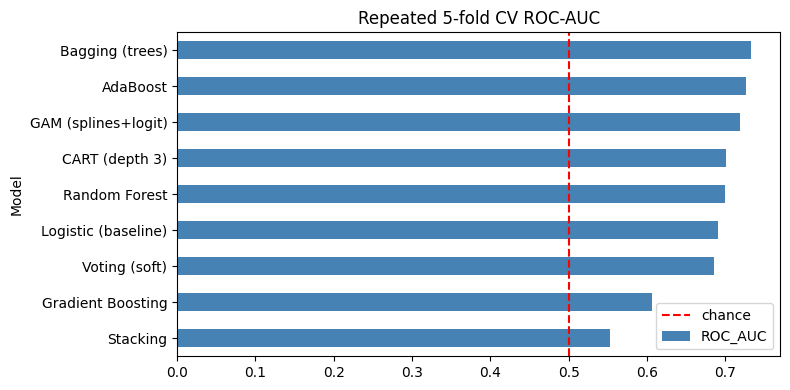

In [21]:
res['ROC_AUC'].sort_values().plot(kind='barh', figsize=(8,4), color='steelblue'); plt.axvline(0.5, color='r', ls='--', label='chance')
plt.title('Repeated 5-fold CV ROC-AUC'); plt.legend(); plt.tight_layout(); plt.show()

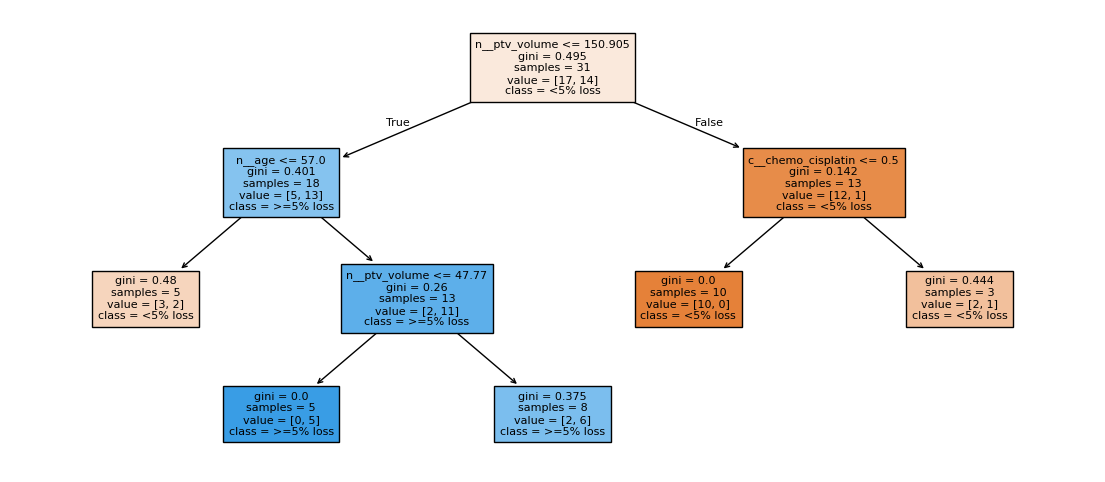

In [23]:
# CART picture - interpretable rules for the viva
from sklearn.tree import plot_tree
cart = models['CART (depth 3)'].fit(X, y)
names = cart.named_steps['p'].get_feature_names_out()
plt.figure(figsize=(14,6)); plot_tree(cart.named_steps['m'], feature_names=names, class_names=['<5% loss','>=5% loss'], filled=True, fontsize=8); plt.show()

### Bayesian Model Averaging (BMA)
Instead of picking one model, weight each by its posterior probability. Here the **posterior weight ∝ exp(−½·BIC)** is approximated for logistic models on different feature subsets; the final prediction is the weighted average of each model's predicted probability.

Top models by posterior weight:
  ('ptv',) 0.286
  ('age', 'ptv') 0.11
  ('ptv', 'bw') 0.058
  ('ptv', 'sex') 0.051
  ('dose',) 0.046


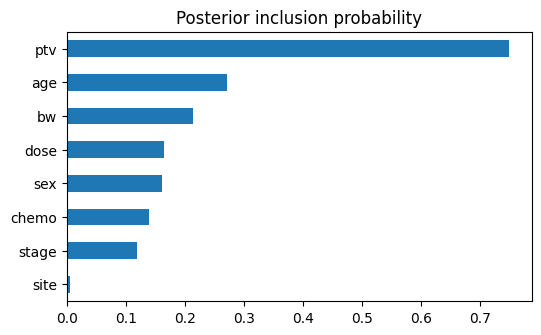

In [24]:
from itertools import combinations
Xd = pd.get_dummies(X, drop_first=True).astype(float)
Xs = pd.DataFrame(StandardScaler().fit_transform(Xd), columns=Xd.columns, index=Xd.index)
groups = {'age':['age'],'ptv':['ptv_volume'],'dose':['dose','fractions'],'bw':['baseline_weight'],
          'sex':[c for c in Xs if c.startswith('sex')],'stage':[c for c in Xs if c.startswith('stage')],
          'site':[c for c in Xs if c.startswith('site')],'chemo':[c for c in Xs if c.startswith('chemo')]}
cands = []
for k in range(1,4):
    for combo in combinations(groups, k):
        cols = sum([groups[g] for g in combo], [])
        lr = LogisticRegression(C=1e6, max_iter=2000).fit(Xs[cols], y)
        p = np.clip(lr.predict_proba(Xs[cols])[:,1],1e-9,1-1e-9)
        ll = np.sum(y*np.log(p)+(1-y)*np.log(1-p)); bic = -2*ll + (len(cols)+1)*np.log(len(y))
        cands.append((combo, cols, bic))
bics = np.array([c[2] for c in cands]); w = np.exp(-0.5*(bics-bics.min())); w /= w.sum()
top = np.argsort(-w)[:5]
print('Top models by posterior weight:'); [print(' ', cands[i][0], round(w[i],3)) for i in top]
# posterior inclusion probability = how likely each feature group is truly useful
pip = {g: sum(w[i] for i,c in enumerate(cands) if g in c[0]) for g in groups}
pd.Series(pip).sort_values().plot(kind='barh', figsize=(6,3.5)); plt.title('Posterior inclusion probability'); plt.show()

# Optional – Image features (links back to your project + Unit 3)
`unsupervised_image_features.csv` has **no labels** (96 colour-histogram values: R, G, B × 32 bins). So we cannot classify it directly; we can discover structure with PCA + GMM/K-means, then *use an ensemble to check that the clusters are learnable*.

PCA components for 95% variance: 23


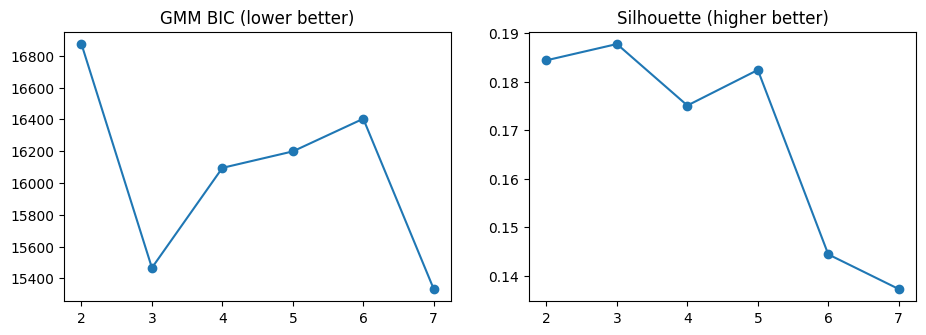

chosen k = 3 cluster sizes: [126 110   1]


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


RF  accuracy predicting clusters: 0.966


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


GB  accuracy predicting clusters: 0.95


In [26]:
from sklearn.decomposition import PCA
from sklearn.mixture import GaussianMixture
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.model_selection import cross_val_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

im = pd.read_csv(IMG); F = im.drop(columns='image_name').values
Z = PCA(n_components=0.95, random_state=0).fit_transform(StandardScaler().fit_transform(F))
print('PCA components for 95% variance:', Z.shape[1])
ks = range(2,8)
bic = [GaussianMixture(k, random_state=0, n_init=3).fit(Z).bic(Z) for k in ks]       # "choosing number of latent dims/clusters"
sil = [silhouette_score(Z, KMeans(k, n_init=10, random_state=0).fit_predict(Z)) for k in ks]
fig,ax = plt.subplots(1,2,figsize=(11,3.5)); ax[0].plot(ks,bic,'o-'); ax[0].set_title('GMM BIC (lower better)'); ax[1].plot(ks,sil,'o-'); ax[1].set_title('Silhouette (higher better)'); plt.show()
k = list(ks)[int(np.argmax(sil))]; lab = KMeans(k, n_init=10, random_state=0).fit_predict(Z)
print('chosen k =', k, 'cluster sizes:', np.bincount(lab))
rf = RandomForestClassifier(150, random_state=0); gb = GradientBoostingClassifier(random_state=0)
print('RF  accuracy predicting clusters:', cross_val_score(rf, Z, lab, cv=5).mean().round(3))
print('GB  accuracy predicting clusters:', cross_val_score(gb, Z, lab, cv=5).mean().round(3))

In [27]:
!pip install mlflow

In [28]:
import mlflow
print(mlflow.__version__)

3.18.0


In [29]:
mlflow.set_experiment("Malicious and Phishing URL Detection")

2026/11/19 06:52:35 INFO mlflow.tracking.fluent: Experiment with name 'Malicious and Phishing URL Detection' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:///content/mlruns/551689411726319686', creation_time=1795071155577, effective_trace_archival_retention=None, experiment_id='551689411726319686', last_update_time=1795071155577, lifecycle_stage='active', name='Malicious and Phishing URL Detection', tags={}, trace_location=None, workspace='default'>

In [30]:
import mlflow
print("MLflow installed successfully!")
print("Version:", mlflow.__version__)

MLflow installed successfully!
Version: 3.18.0


In [31]:
import mlflow
import mlflow.sklearn

print("MLflow installed successfully!")
print("Version:", mlflow.__version__)

MLflow installed successfully!
Version: 3.18.0


In [32]:
import os
import mlflow

# Enable the filesystem tracking backend in newer MLflow versions
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

mlflow.set_tracking_uri("file:///content/mlruns")

mlflow.set_experiment("Early Oral Cancer Screening")

print("MLflow Experiment Created Successfully!")

2026/11/19 06:52:42 INFO mlflow.tracking.fluent: Experiment with name 'Early Oral Cancer Screening' does not exist. Creating a new experiment.


MLflow Experiment Created Successfully!


In [33]:
res = pd.DataFrame(rows, columns=['Model','Accuracy','Acc_std','ROC_AUC','F1']).set_index('Model').round(3)

In [34]:
import mlflow
import mlflow.sklearn

for name, model in models.items():

    with mlflow.start_run(run_name=name):

        # Train the model
        model.fit(X, y)

        # Log model parameters
        mlflow.log_param("Model_Name", name)
        mlflow.log_param("CV_Method", "Repeated Stratified 5-Fold")
        mlflow.log_param("Number_of_Repeats", 3)

        # Log evaluation metrics from existing cross-validation results
        mlflow.log_metric("Accuracy", float(res.loc[name, "Accuracy"]))
        mlflow.log_metric("Accuracy_Std", float(res.loc[name, "Acc_std"]))
        mlflow.log_metric("ROC_AUC", float(res.loc[name, "ROC_AUC"]))
        mlflow.log_metric("F1_Score", float(res.loc[name, "F1"]))

        # Save trained model using standard pickle serialization
        mlflow.sklearn.log_model(
            sk_model=model,
            artifact_path="model",
            serialization_format="pickle"
        )

        print(name, "logged successfully!")

print("All models tracked successfully in MLflow!")

2026/11/19 06:52:48 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:52:48 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/19 06:52:56 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:52:56 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_p

Logistic (baseline) logged successfully!


2026/11/19 06:53:00 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:53:00 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


CART (depth 3) logged successfully!
GAM (splines+logit) logged successfully!


2026/11/19 06:53:05 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:53:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Bagging (trees) logged successfully!


... (4 outputs left out)

2026/11/19 06:53:24 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:53:24 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Voting (soft) logged successfully!


2026/11/19 06:53:30 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.
2026/11/19 06:53:30 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Stacking logged successfully!
All models tracked successfully in MLflow!


In [35]:
import mlflow
import json

with mlflow.start_run(run_name="Hidden Markov Model"):

    mlflow.log_param("Model", "HMM")
    mlflow.log_param("Hidden_States", 2)
    mlflow.log_param("Observation_Symbols", 3)
    mlflow.log_param("Algorithm", "Baum-Welch")
    mlflow.log_metric("Final_Log_Likelihood", float(ll_hist[-1]))

    mlflow.log_param("Initial_Probabilities", json.dumps(pi.tolist()))
    mlflow.log_param("Transition_Matrix", json.dumps(A.tolist()))
    mlflow.log_param("Emission_Matrix", json.dumps(B.tolist()))

print("HMM tracked successfully!")

HMM tracked successfully!


In [36]:
!mlflow ui --backend-store-uri file:///content/mlruns --host 0.0.0.0 --port 5000 > /content/mlflow_ui.log 2>&1 &

In [37]:
from google.colab.output import eval_js
from IPython.display import HTML, display

url = eval_js("google.colab.kernel.proxyPort(5000)")

display(HTML(f'<a href="{url}" target="_blank">Open MLflow Dashboard</a>'))

In [38]:
!cat /content/mlflow_ui.log

Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/11/19 06:53:50 WARNING mlflow.server: MLflow job execution requirements not met (MLflow job backend requires a database backend store URI but got file:///content/mlruns). Server will start without job execution support. Errors will be surfaced at job invocation time.
2026/11/19 06:53:50 INFO:     Uvicorn running on http://0.0.0.0:5000 (Press CTRL+C to quit)
2026/11/19 06:53:50 INFO:     Started parent process [6689]


In [39]:
from google.colab.output import eval_js
from IPython.display import display, HTML

url = eval_js("google.colab.kernel.proxyPort(5000)")

display(HTML(f'<a href="{url}" target="_blank">Open MLflow Dashboard</a>'))

In [40]:
import subprocess
import sys
import time

log_file = open("/content/mlflow_fixed.log", "w")

mlflow_server = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "ui",
        "--backend-store-uri", "file:///content/mlruns",
        "--host", "0.0.0.0",
        "--port", "5001",
        "--allowed-hosts", "*",
        "--cors-allowed-origins", "*"
    ],
    stdout=log_file,
    stderr=subprocess.STDOUT
)

time.sleep(5)

print("Server status:", "Running" if mlflow_server.poll() is None else "Stopped")
print(open("/content/mlflow_fixed.log").read()[-2000:])

Server status: Running



In [41]:
from google.colab.output import eval_js
from IPython.display import HTML, display

url = eval_js("google.colab.kernel.proxyPort(5001)")
display(HTML(f'<a href="{url}" target="_blank">Open MLflow Dashboard</a>'))

In [42]:
import os
import subprocess

print("=== MLflow process ===")
os.system("ps aux | grep '[m]lflow'")

print("\n=== Port 5001 ===")
os.system("ss -ltnp | grep 5001")

print("\n=== MLflow error log ===")
if os.path.exists("/content/mlflow_fixed.log"):
    print(open("/content/mlflow_fixed.log").read()[-5000:])
else:
    print("Log file not found")

=== MLflow process ===

=== Port 5001 ===

=== MLflow error log ===
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *. CORS origins: *.
2026/11/19 06:54:13 WARNING mlflow.server: MLflow job execution requirements not met (MLflow job backend requires a database backend store URI but got file:///content/mlruns). Server will start without job execution support. Errors will be surfaced at job invocation time.
2026/11/19 06:54:13 INFO:     Uvicorn running on http://0.0.0.0:5001 (Press CTRL+C to quit)
2026/11/19 06:54:13 INFO:     Started parent process [6825]



In [43]:
import subprocess
import sys
import time
import requests

log = open("/content/mlflow_final.log", "w")

cmd = [
    sys.executable, "-m", "mlflow", "ui",
    "--backend-store-uri", "file:///content/mlruns",
    "--host", "0.0.0.0",
    "--port", "5002",
    "--workers", "1",
    "--allowed-hosts", "*",
    "--cors-allowed-origins", "*"
]

server = subprocess.Popen(
    cmd,
    stdin=subprocess.DEVNULL,
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

print("Process status:", server.poll())
print("Server response:")

try:
    r = requests.get("http://127.0.0.1:5002/", timeout=10)
    print("HTTP Status:", r.status_code)
    print("MLflow is responding!")
except Exception as e:
    print("ERROR:", repr(e))

print("\nSERVER LOG:")
print(open("/content/mlflow_final.log").read()[-3000:])

Process status: None
Server response:
HTTP Status: 200
MLflow is responding!

SERVER LOG:
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                              

In [44]:
from google.colab.output import eval_js
from IPython.display import HTML, display

url = eval_js("google.colab.kernel.proxyPort(5002)")
display(HTML(f'<a href="{url}" target="_blank">CLICK HERE — OPEN MLFLOW</a>'))

In [45]:

import mlflow
import mlflow.sklearn
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Check MLflow connection
print("MLflow Version:", mlflow.__version__)
print("Tracking URI:", mlflow.get_tracking_uri())

# Create/select your experiment
mlflow.set_experiment("Early Oral Cancer Screening")

print("MLflow experiment configured successfully!")


MLflow Version: 3.18.0
Tracking URI: file:///content/mlruns
MLflow experiment configured successfully!


Final HMM Log Likelihood: -52.78786210019278


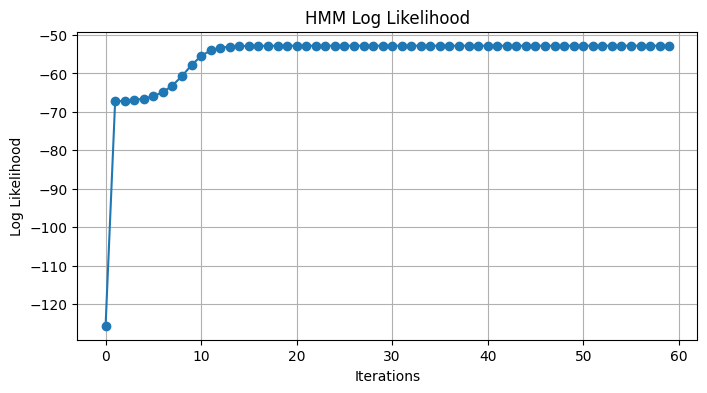

HMM metrics and artifacts logged successfully!
Run ID: bb3c66d4ebdb449c89d61f8036f212b0


In [46]:

# ==========================================
# UNIT 4: HMM - MLFLOW METRICS AND ARTIFACTS
# ==========================================

with mlflow.start_run(run_name="Hidden Markov Model") as run:

    # 1. Log parameters
    mlflow.log_params({
        "model": "Hidden Markov Model",
        "hidden_states": 2,
        "observation_symbols": 3,
        "algorithm": "Baum-Welch",
        "decoding": "Viterbi",
        "iterations": len(ll_hist),
        "patients": len(OBS)
    })

    # 2. Log likelihood at every iteration
    for step, value in enumerate(ll_hist):
        mlflow.log_metric(
            "Log_Likelihood",
            float(value),
            step=step
        )

    # 3. Log final metrics
    final_ll = float(ll_hist[-1])

    mlflow.log_metric("Final_Log_Likelihood", final_ll)

    print("Final HMM Log Likelihood:", final_ll)

    # 4. Create artifact folder
    with tempfile.TemporaryDirectory() as folder:

        # Save transition matrix
        pd.DataFrame(A).to_csv(
            os.path.join(folder, "Transition_Matrix.csv"),
            index=False
        )

        # Save emission matrix
        pd.DataFrame(B).to_csv(
            os.path.join(folder, "Emission_Matrix.csv"),
            index=False
        )

        # Save initial probabilities
        pd.DataFrame({
            "Initial_Probability": pi
        }).to_csv(
            os.path.join(folder, "Initial_Probabilities.csv"),
            index=False
        )

        # Save HMM parameters
        np.savez(
            os.path.join(folder, "HMM_Parameters.npz"),
            pi=pi, A=A, B=B
        )

        # 5. Create likelihood graph
        plt.figure(figsize=(8, 4))
        plt.plot(ll_hist, marker='o')
        plt.title("HMM Log Likelihood")
        plt.xlabel("Iterations")
        plt.ylabel("Log Likelihood")
        plt.grid(True)

        graph_path = os.path.join(
            folder, "HMM_Log_Likelihood.png"
        )

        plt.savefig(graph_path, bbox_inches="tight")
        plt.show()
        plt.close()

        # 6. Save patient predictions
        hmm_results = P[
            ["target", "final_state", "loglik"]
        ].copy()

        hmm_results.to_csv(
            os.path.join(folder, "HMM_Patient_Results.csv")
        )

        # 7. Upload all files to MLflow
        mlflow.log_artifacts(folder, artifact_path="HMM_Artifacts")

    print("HMM metrics and artifacts logged successfully!")
    print("Run ID:", run.info.run_id)


MODEL PERFORMANCE COMPARISON


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
Logistic (baseline),0.6143,0.5656,0.5444,0.5178,0.6907
CART (depth 3),0.6349,0.5711,0.4556,0.4746,0.7009
GAM (splines+logit),0.6444,0.6778,0.4111,0.4737,0.7176
Bagging (trees),0.6365,0.6711,0.5444,0.5711,0.7333
Random Forest,0.6476,0.6267,0.5444,0.5600,0.6991
AdaBoost,0.6603,0.6489,0.5889,0.5803,0.7259
Gradient Boosting,0.5587,0.5100,0.4556,0.4505,0.6065
Voting (soft),0.6556,0.6600,0.5222,0.5406,0.6861
Stacking,0.5444,0.1167,0.1000,0.1022,0.5528


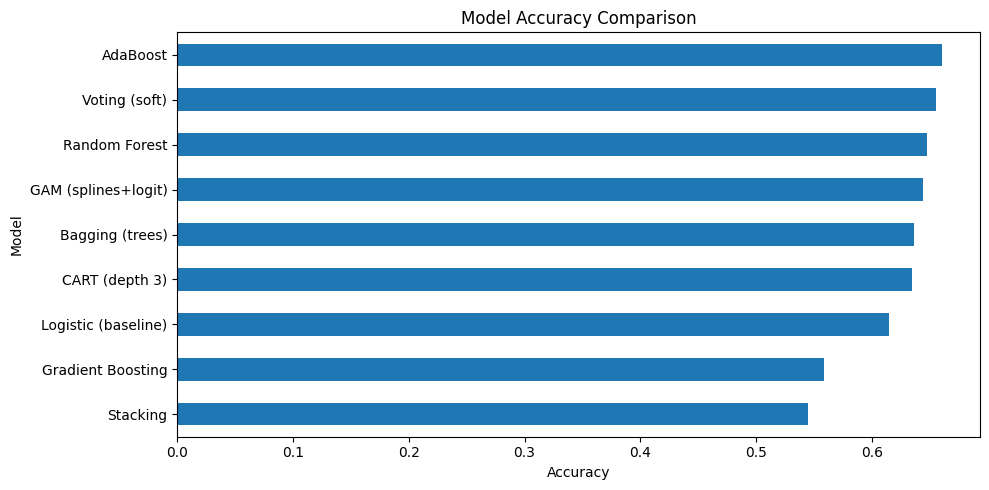

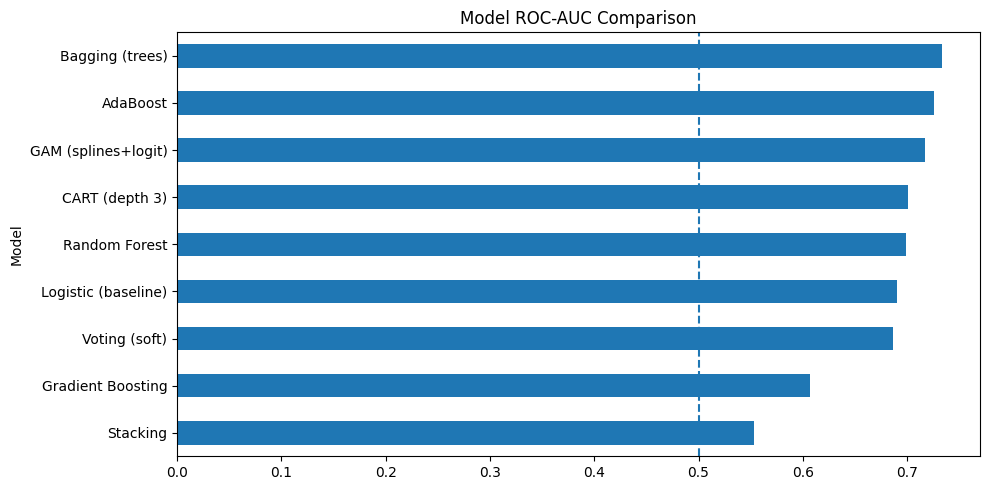

2026/11/19 06:55:27 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html
2026/11/19 06:55:32 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged: Logistic (baseline) | Run ID: 86ee4f9ae00844319f6a73e6288c1748


2026/11/19 06:55:36 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged: CART (depth 3) | Run ID: b95ed6f4d1c640c590bf23ee7f9e8785
Logged: GAM (splines+logit) | Run ID: 47d4b9f919d547b6a4336e8397c3d9ef


2026/11/19 06:55:41 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged: Bagging (trees) | Run ID: e197a89ddc1a45aba2eaf2270da93fbe


... (4 outputs left out)

2026/11/19 06:56:01 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged: Voting (soft) | Run ID: 0b3ef46c24804cd8a34d79e22d62b13a


2026/11/19 06:56:06 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


Logged: Stacking | Run ID: bc505d6b867747e5bbce87684449b600

ALL UNIT 5 MODELS LOGGED SUCCESSFULLY!


In [47]:

# ==========================================
# UNIT 5: MODEL METRICS AND MLFLOW LOGGING
# ==========================================

from sklearn.model_selection import cross_validate
import os
import tempfile
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn

# Calculate all evaluation metrics
scoring = [
    "accuracy",
    "precision",
    "recall",
    "f1",
    "roc_auc"
]

rows = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X,
        y,
        cv=cv,
        scoring=scoring,
        n_jobs=-1
    )

    rows.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC_AUC": scores["test_roc_auc"].mean()
    })

res = pd.DataFrame(rows).set_index("Model").round(4)

print("MODEL PERFORMANCE COMPARISON")
display(res)

# Save common comparison files
with tempfile.TemporaryDirectory() as folder:

    csv_path = os.path.join(folder, "Model_Comparison.csv")
    res.to_csv(csv_path)

    # Accuracy graph
    plt.figure(figsize=(10, 5))
    res["Accuracy"].sort_values().plot(
        kind="barh",
        title="Model Accuracy Comparison"
    )
    plt.xlabel("Accuracy")
    plt.tight_layout()

    accuracy_path = os.path.join(
        folder, "Accuracy_Comparison.png"
    )

    plt.savefig(accuracy_path, bbox_inches="tight")
    plt.show()
    plt.close()

    # ROC-AUC graph
    plt.figure(figsize=(10, 5))
    res["ROC_AUC"].sort_values().plot(
        kind="barh",
        title="Model ROC-AUC Comparison"
    )
    plt.axvline(0.5, linestyle="--")
    plt.tight_layout()

    roc_path = os.path.join(
        folder, "ROC_AUC_Comparison.png"
    )

    plt.savefig(roc_path, bbox_inches="tight")
    plt.show()
    plt.close()

    # Log each model as a separate MLflow run
    for name, model in models.items():

        with mlflow.start_run(run_name=name) as run:

            # Log parameters
            mlflow.log_params({
                "model_name": name,
                "cross_validation": "Repeated Stratified 5-Fold",
                "patients": len(X)
            })

            # Get metrics
            metrics = {
                key: float(res.loc[name, key])
                for key in [
                    "Accuracy",
                    "Precision",
                    "Recall",
                    "F1",
                    "ROC_AUC"
                ]
            }

            # Log metrics to run
            mlflow.log_metrics(metrics)

            # Train final model on complete dataset
            model.fit(X, y)

            # Log trained model utilizing the standard pickle format to bypass skops validation issues
            model_info = mlflow.sklearn.log_model(
                sk_model=model,
                name="trained_model",
                serialization_format="pickle"
            )

            # Associate metrics with logged model
            mlflow.log_metrics(
                metrics,
                model_id=model_info.model_id
            )

            # Upload comparison files
            mlflow.log_artifact(csv_path)
            mlflow.log_artifact(accuracy_path)
            mlflow.log_artifact(roc_path)

            print("Logged:", name, "| Run ID:", run.info.run_id)

print("\nALL UNIT 5 MODELS LOGGED SUCCESSFULLY!")

In [48]:
import subprocess
import sys
import time
import requests

log = open("/content/mlflow_final.log", "w")

cmd = [
    sys.executable, "-m", "mlflow", "ui",
    "--backend-store-uri", "file:///content/mlruns",
    "--host", "0.0.0.0",
    "--port", "5002",
    "--workers", "1",
    "--allowed-hosts", "*",
    "--cors-allowed-origins", "*"
]

server = subprocess.Popen(
    cmd,
    stdin=subprocess.DEVNULL,
    stdout=log,
    stderr=subprocess.STDOUT,
    start_new_session=True
)

time.sleep(10)

print("Process status:", server.poll())
print("Server response:")

try:
    r = requests.get("http://127.0.0.1:5002/", timeout=10)
    print("HTTP Status:", r.status_code)
    print("MLflow is responding!")
except Exception as e:
    print("ERROR:", repr(e))

print("\nSERVER LOG:")
print(open("/content/mlflow_final.log").read()[-3000:])

Process status: None
Server response:
HTTP Status: 200
MLflow is responding!

SERVER LOG:
gins with credentials is a CORS spec violation. Set an explicit origin allowlist to enable credentialed cross-origin requests.
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:24: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi import WSGIResponder, build_environ
2026/11/19 06:56:44 WARNING mlflow.server.fastapi_security: MLFLOW_SERVER_CORS_ALLOWED_ORIGINS=* is set; disabling credentialed CORS. Wildcard origins with credentials is a CORS spec violation. Set an explicit origin allowlist to enable credentialed cross-origin requests.
2026/11/19 06:56:44 INFO:     Started server process [7568]
2026/11/19 06:56:44 INFO:     Waiting for application startup.
2026/11/19 06:56:45 INFO:     Application startup complete.
202

In [49]:
from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(5002)")

print("Your MLflow Dashboard URL:")
print(url)

Your MLflow Dashboard URL:
https://5002-m-s-usc1c13-2awns2u6tk0w0-c.us-central1.prod.r.colab.dev


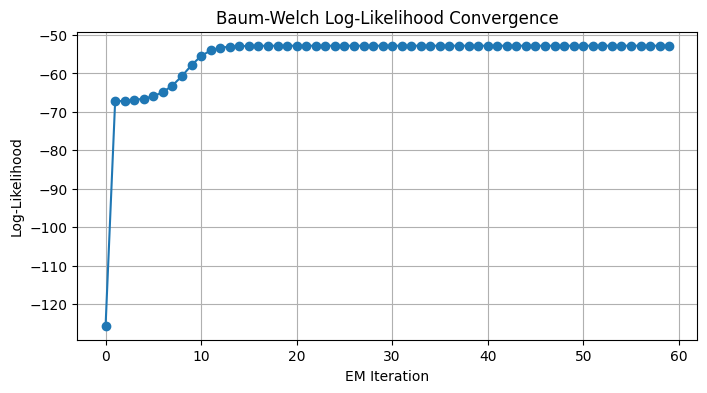

SUCCESS! All four HMM algorithms logged in MLflow.
Forward, Backward, Viterbi and Baum-Welch runs created.


In [50]:

# ==========================================
# HMM: LOG ALL FOUR ALGORITHMS IN MLFLOW
# Run this AFTER Cell 9
# ==========================================

import mlflow
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Connect to your existing MLflow tracking store
mlflow.set_tracking_uri("file:///content/mlruns")
mlflow.set_experiment("Early Oral Cancer Screening")

artifact_dir = "/content/HMM_Artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# ------------------------------------------
# 1. FORWARD ALGORITHM
# ------------------------------------------

forward_results = []

for i, obs in enumerate(OBS):
    alpha, c = forward(obs, pi, A, B)
    log_likelihood = np.log(c).sum()

    for t in range(len(obs)):
        for state in range(len(pi)):
            forward_results.append({
                "Patient": i + 1,
                "Time": t,
                "Hidden_State": state,
                "Forward_Probability": alpha[t, state]
            })

forward_df = pd.DataFrame(forward_results)
forward_df.to_csv(
    f"{artifact_dir}/forward_probabilities.csv", index=False
)

with mlflow.start_run(run_name="HMM - Forward Algorithm"):
    mlflow.log_param("algorithm", "Forward")
    mlflow.log_param("number_of_patients", len(OBS))
    mlflow.log_metric(
        "mean_log_likelihood",
        float(np.mean([
            np.log(forward(o, pi, A, B)[1]).sum()
            for o in OBS
        ]))
    )
    mlflow.log_artifact(
        f"{artifact_dir}/forward_probabilities.csv"
    )

# ------------------------------------------
# 2. BACKWARD ALGORITHM
# ------------------------------------------

backward_results = []

for i, obs in enumerate(OBS):
    alpha, c = forward(obs, pi, A, B)
    beta = backward(obs, A, B, c)

    for t in range(len(obs)):
        for state in range(len(pi)):
            backward_results.append({
                "Patient": i + 1,
                "Time": t,
                "Hidden_State": state,
                "Backward_Probability": beta[t, state]
            })

backward_df = pd.DataFrame(backward_results)
backward_df.to_csv(
    f"{artifact_dir}/backward_probabilities.csv", index=False
)

with mlflow.start_run(run_name="HMM - Backward Algorithm"):
    mlflow.log_param("algorithm", "Backward")
    mlflow.log_param("number_of_patients", len(OBS))
    mlflow.log_metric(
        "mean_backward_probability",
        float(backward_df["Backward_Probability"].mean())
    )
    mlflow.log_artifact(
        f"{artifact_dir}/backward_probabilities.csv"
    )

# ------------------------------------------
# 3. VITERBI ALGORITHM
# ------------------------------------------

viterbi_results = []

for i, obs in enumerate(OBS):
    path = viterbi(obs, pi, A, B)

    for t, state in enumerate(path):
        viterbi_results.append({
            "Patient": i + 1,
            "Time": t,
            "Observation": obs[t],
            "Predicted_Hidden_State": state
        })

viterbi_df = pd.DataFrame(viterbi_results)
viterbi_df.to_csv(
    f"{artifact_dir}/viterbi_sequences.csv", index=False
)

with mlflow.start_run(run_name="HMM - Viterbi Algorithm"):
    mlflow.log_param("algorithm", "Viterbi")
    mlflow.log_param("number_of_patients", len(OBS))
    mlflow.log_metric(
        "mean_final_state",
        float(np.mean([p[-1] for p in paths]))
    )
    mlflow.log_artifact(
        f"{artifact_dir}/viterbi_sequences.csv"
    )

# ------------------------------------------
# 4. BAUM-WELCH ALGORITHM
# ------------------------------------------

plt.figure(figsize=(8, 4))
plt.plot(ll_hist, marker="o")
plt.title("Baum-Welch Log-Likelihood Convergence")
plt.xlabel("EM Iteration")
plt.ylabel("Log-Likelihood")
plt.grid(True)

baum_plot = f"{artifact_dir}/baum_welch_convergence.png"
plt.savefig(baum_plot, bbox_inches="tight")
plt.show()
plt.close()

np.savetxt(
    f"{artifact_dir}/transition_matrix.csv", A, delimiter=","
)
np.savetxt(
    f"{artifact_dir}/emission_matrix.csv", B, delimiter=","
)
np.savetxt(
    f"{artifact_dir}/initial_probabilities.csv", pi, delimiter=","
)

with mlflow.start_run(run_name="HMM - Baum-Welch Algorithm"):
    mlflow.log_param("algorithm", "Baum-Welch")
    mlflow.log_param("number_of_iterations", len(ll_hist))
    mlflow.log_param("random_restarts", 10)
    mlflow.log_metric(
        "final_log_likelihood", float(ll_hist[-1])
    )
    mlflow.log_artifacts(artifact_dir)

print("SUCCESS! All four HMM algorithms logged in MLflow.")
print("Forward, Backward, Viterbi and Baum-Welch runs created.")


In [51]:

import os

print("Current location:", os.getcwd())

print("\nFiles in /content:")
print(os.listdir("/content"))

print("\nCSV files found:")
for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))


Current location: /content

Files in /content:
['.config', 'unsupervised_image_features.csv', 'HMM_Artifacts', 'mlruns', 'Unit4_5_ML_Flow_HNSCC.ipynb', 'mlflow_ui.log', 'mlflow_final.log', 'mlflow_fixed.log', 'HNSCC_sequential_clinical_long.csv', 'sample_data']

CSV files found:
/content/unsupervised_image_features.csv
/content/HNSCC_sequential_clinical_long.csv
/content/HMM_Artifacts/forward_probabilities.csv
/content/HMM_Artifacts/backward_probabilities.csv
/content/HMM_Artifacts/viterbi_sequences.csv
/content/HMM_Artifacts/initial_probabilities.csv
/content/HMM_Artifacts/emission_matrix.csv
/content/HMM_Artifacts/transition_matrix.csv
/content/mlruns/900602169069236939/50cb181b0aa845bfaa9eb3f8149dd6e3/artifacts/Model_Comparison.csv
/content/mlruns/900602169069236939/0b3ef46c24804cd8a34d79e22d62b13a/artifacts/Model_Comparison.csv
/content/mlruns/900602169069236939/bc505d6b867747e5bbce87684449b600/artifacts/Model_Comparison.csv
/content/mlruns/900602169069236939/b0f6466cd4814c2fa4ef44

In [52]:

import os

print("Files in root folder:")
print(os.listdir("/"))

print("\nChecking possible dataset locations:")

for path in [
    "/HNSCC_sequential_clinical_long.csv",
    "/unsupervised_image_features.csv",
    "/content/HNSCC_sequential_clinical_long.csv",
    "/content/drive/MyDrive"
]:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")


Files in root folder:
['bin', 'sbin', 'lib', 'opt', 'media', 'usr', 'proc', 'var', 'sys', 'mnt', 'lib64', 'dev', 'tmp', 'root', 'boot', 'etc', 'run', 'srv', 'home', 'kaggle', 'content', '.dockerenv', 'backend-container', 'tools', 'datalab', 'python-apt', 'python-apt.tar.xz', 'sbin.usr-is-merged', 'bin.usr-is-merged', 'lib.usr-is-merged']

Checking possible dataset locations:
/HNSCC_sequential_clinical_long.csv NOT FOUND
/unsupervised_image_features.csv NOT FOUND
/content/HNSCC_sequential_clinical_long.csv EXISTS
/content/drive/MyDrive NOT FOUND


In [53]:

import os

print("RUNTIME STATUS")
print("Current directory:", os.getcwd())

print("\nDATASET LOCATIONS")

files = [
    "HNSCC_sequential_clinical_long.csv",
    "unsupervised_image_features.csv"
]

for file in files:
    for folder in ["/content", "/"]:
        path = os.path.join(folder, file)
        if os.path.exists(path):
            print("FOUND:", path)

print("\nMLFLOW DATA")

for path in ["/content/mlruns", "/mlruns"]:
    print(path, "EXISTS" if os.path.exists(path) else "NOT FOUND")

print("\nMLFLOW PACKAGE")

try:
    import mlflow
    print("MLflow version:", mlflow.__version__)
except Exception as e:
    print("MLflow error:", e)


RUNTIME STATUS
Current directory: /content

DATASET LOCATIONS
FOUND: /content/HNSCC_sequential_clinical_long.csv
FOUND: /content/unsupervised_image_features.csv

MLFLOW DATA
/content/mlruns EXISTS
/mlruns NOT FOUND

MLFLOW PACKAGE
MLflow version: 3.18.0


In [54]:
import os

print("Current location:", os.getcwd())

print("Clinical dataset:",
      os.path.exists("/HNSCC_sequential_clinical_long.csv"))

print("Image dataset:",
      os.path.exists("/unsupervised_image_features.csv"))

print("MLflow folder:",
      os.path.exists("/content/mlruns"))

Current location: /content
Clinical dataset: False
Image dataset: False
MLflow folder: True


In [55]:
import sys
import subprocess

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "mlflow"
])

import mlflow

print("MLflow version:", mlflow.__version__)
print("MLflow installed successfully!")

MLflow version: 3.18.0
MLflow installed successfully!


In [56]:
import os

path = "/content/mlruns"

print("MLflow folder exists:", os.path.exists(path))

if os.path.exists(path):
    print("Files:", os.listdir(path)[:10])

MLflow folder exists: True
Files: ['.trash', '0', '551689411726319686', 'models', '900602169069236939']


In [57]:
import subprocess
import sys
import time
import requests

log = open("/content/mlflow_final.log", "w")

cmd = [
    sys.executable, "-m", "mlflow", "ui",
    "--backend-store-uri", "file:///content/mlruns",
    "--host", "0.0.0.0",
    "--port", "5002"
]

process = subprocess.Popen(
    cmd,
    stdout=log,
    stderr=subprocess.STDOUT
)

time.sleep(10)

try:
    response = requests.get("http://127.0.0.1:5002")
    print("MLflow Status:", response.status_code)
    print("MLflow server is running!")
except Exception as e:
    print("Error:", e)

MLflow Status: 200
MLflow server is running!


In [58]:

import os
import sys
import requests
import subprocess

print("Python:", sys.version)
print("MLflow folder exists:", os.path.exists("/content/mlruns"))

if os.path.exists("/content/mlruns"):
    print("Tracking files:", os.listdir("/content/mlruns")[:20])

try:
    import mlflow
    print("MLflow version:", mlflow.__version__)
except Exception as e:
    print("MLflow error:", e)

try:
    r = requests.get("http://127.0.0.1:5002")
    print("Dashboard status:", r.status_code)
except Exception as e:
    print("Dashboard not running:", e)


Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
MLflow folder exists: True
Tracking files: ['.trash', '0', '551689411726319686', 'models', '900602169069236939']
MLflow version: 3.18.0
Dashboard status: 200


### 🚀 Access the MLflow Dashboard
Run the cell below to generate the public proxy URL and open your MLflow experiment runs dashboard.

In [61]:
from google.colab.output import eval_js
from IPython.display import HTML, display

# Generate the secure proxy link for local port 5002
url = eval_js("google.colab.kernel.proxyPort(5002)")

display(HTML(f'<h3>🔗 <a href="{url}" target="_blank">CLICK HERE TO OPEN MLFLOW DASHBOARD</a></h3>'))
print(f"Direct URL: {url}")

Direct URL: https://5002-m-s-usc1c13-2awns2u6tk0w0-c.us-central1.prod.r.colab.dev


In [62]:

import os
import sys
import time
import subprocess
import requests

# MLflow settings
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

TRACKING_PATH = "/content/mlruns"

# Check existing tracking data
if not os.path.exists(TRACKING_PATH):
    raise FileNotFoundError(
        "MLflow tracking folder not found!"
    )

print("MLflow tracking folder found!")

# Check whether an MLflow server is already running
MLFLOW_PORT = None
server_process = None

for port in [5002, 5003, 5004]:
    try:
        response = requests.get(
            f"http://127.0.0.1:{port}",
            timeout=2
        )
        if response.status_code == 200:
            MLFLOW_PORT = port
            print("Existing MLflow server found!")
            break
    except requests.exceptions.RequestException:
        pass

# Start server if needed
if MLFLOW_PORT is None:

    for port in [5002, 5003, 5004]:

        log_file = open(
            f"/content/mlflow_{port}.log", "w"
        )

        server_process = subprocess.Popen(
            [
                sys.executable, "-m", "mlflow", "ui",
                "--backend-store-uri",
                "file:///content/mlruns",
                "--host", "0.0.0.0",
                "--port", str(port)
            ],
            stdout=log_file,
            stderr=subprocess.STDOUT,
            env=os.environ.copy()
        )

        for attempt in range(10):
            time.sleep(2)

            try:
                response = requests.get(
                    f"http://127.0.0.1:{port}",
                    timeout=3
                )

                if response.status_code == 200:
                    MLFLOW_PORT = port
                    break

            except requests.exceptions.RequestException:
                pass

            if server_process.poll() is not None:
                break

        if MLFLOW_PORT is not None:
            break

if MLFLOW_PORT is None:
    raise RuntimeError(
        "MLflow server failed. Check /content/mlflow_5002.log"
    )

print("--------------------------------")
print("MLFLOW DASHBOARD RUNNING!")
print("Port:", MLFLOW_PORT)
print("Status: 200 OK")
print("--------------------------------")


MLflow tracking folder found!


RuntimeError: MLflow server failed. Check /content/mlflow_5002.log

In [63]:

import os

for port in [5002, 5003, 5004]:
    path = f"/content/mlflow_{port}.log"

    if os.path.exists(path):
        print(f"\n========== PORT {port} LOG ==========")

        with open(path, "r") as f:
            print(f.read()[-4000:])



========== PORT 5002 LOG ==========
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled with default settings (localhost-only). To allow connections from other hosts, use --host 0.0.0.0 and configure --allowed-hosts and --cors-allowed-origins.
2026/11/19 07:00:46 WARNING mlflow.server: MLflow job execution requirements not met (MLflow job backend requires a database backend store URI but got file:///content/mlruns). Server will start without job execution support. Errors will be surfaced at job invocation time.
2026/11/19 07:00:47 INFO:     Uvicorn running on http://0.0.0.0:5002 (Press CTRL+C to quit)
2026/11/19 07:00:47 INFO:     Started parent process [8683]
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:24: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi

In [64]:

from google.colab import output
import requests

# Find working MLflow port
for port in [5002, 5003, 5004]:
    try:
        r = requests.get(
            f"http://127.0.0.1:{port}",
            timeout=5
        )
        if r.status_code == 200:
            MLFLOW_PORT = port
            print("MLflow is running on port:", port)
            break
    except:
        continue

output.serve_kernel_port_as_iframe(
    MLFLOW_PORT,
    height=800
)


MLflow is running on port: 5002


<IPython.core.display.Javascript object>

In [65]:

import os
import sys
import time
import subprocess
import requests
import psutil

os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Stop previous MLflow UI processes
for p in psutil.process_iter(["pid", "cmdline"]):
    try:
        cmd = " ".join(p.info["cmdline"] or [])
        if "mlflow" in cmd.lower() and "ui" in cmd.lower():
            if p.pid != os.getpid():
                p.terminate()
    except (psutil.NoSuchProcess, psutil.AccessDenied):
        pass

time.sleep(3)

# Start MLflow with Colab-compatible host settings
log = open("/content/mlflow_review.log", "w")

process = subprocess.Popen(
    [
        sys.executable, "-m", "mlflow", "ui",
        "--backend-store-uri", "file:///content/mlruns",
        "--host", "0.0.0.0",
        "--port", "5002",
        "--allowed-hosts", "*",
        "--cors-allowed-origins", "*",
        "--workers", "1"
    ],
    stdout=log,
    stderr=subprocess.STDOUT,
    env=os.environ.copy()
)

# Wait for server
for i in range(20):
    time.sleep(2)
    try:
        r = requests.get("http://127.0.0.1:5002", timeout=5)
        if r.status_code == 200:
            print("MLFLOW SERVER: RUNNING")
            print("STATUS:", r.status_code)
            break
    except requests.exceptions.RequestException:
        pass
else:
    raise RuntimeError("Check /content/mlflow_review.log")

# Open dashboard
from google.colab import output

output.serve_kernel_port_as_iframe(5002, height=800)


MLFLOW SERVER: RUNNING
STATUS: 200


<IPython.core.display.Javascript object>

In [66]:

import requests
import subprocess
import os

print("LOCAL SERVER CHECK")

try:
    r = requests.get("http://127.0.0.1:5002", timeout=5)
    print("Status:", r.status_code)
except Exception as e:
    print("Local error:", e)

print("\nSERVER LOG")

if os.path.exists("/content/mlflow_review.log"):
    print(open("/content/mlflow_review.log").read()[-3000:])

print("\nPORT CHECK")

!ps aux | grep '[m]lflow'


LOCAL SERVER CHECK
Status: 200

SERVER LOG
Registry store URI not provided. Using backend store URI.
[MLflow] Security middleware enabled. Allowed hosts: *. CORS origins: *.
2026/11/19 07:04:51 WARNING mlflow.server: MLflow job execution requirements not met (MLflow job backend requires a database backend store URI but got file:///content/mlruns). Server will start without job execution support. Errors will be surfaced at job invocation time.
2026/11/19 07:04:55 WARNING mlflow.server.security: MLFLOW_SERVER_CORS_ALLOWED_ORIGINS=* is set; disabling credentialed CORS. Wildcard origins with credentials is a CORS spec violation. Set an explicit origin allowlist to enable credentialed cross-origin requests.
/usr/local/lib/python3.13/dist-packages/mlflow/server/fastapi_app.py:24: StarletteDeprecationWarning: starlette.middleware.wsgi is deprecated and will be removed in a future release. Please refer to https://github.com/abersheeran/a2wsgi as a replacement.
  from starlette.middleware.wsgi 

In [67]:
from google.colab import output

output.serve_kernel_port_as_window(5002)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

In [68]:

from google.colab.output import eval_js

url = eval_js("google.colab.kernel.proxyPort(5002)")
print("YOUR MLFLOW DASHBOARD LINK:")
print(url)


YOUR MLFLOW DASHBOARD LINK:
https://5002-m-s-usc1c13-2awns2u6tk0w0-c.us-central1.prod.r.colab.dev


In [70]:

import os
import sys
import time
import subprocess
import requests

# Enable existing MLflow file tracking
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

# Check tracking folder
if not os.path.exists("/content/mlruns"):
    raise FileNotFoundError(
        "mlruns folder missing. Previous tracking data needs to be restored."
    )

# Check if server is already running
port = 5002

try:
    r = requests.get(
        f"http://127.0.0.1:{port}",
        timeout=3
    )
    print("Existing MLflow server is running!")

except requests.exceptions.RequestException:

    log = open("/content/mlflow_review.log", "w")

    process = subprocess.Popen(
        [
            sys.executable, "-m", "mlflow", "ui",
            "--backend-store-uri", "file:///content/mlruns",
            "--host", "0.0.0.0",
            "--port", str(port),
            "--allowed-hosts", "*",
            "--cors-allowed-origins", "*",
            "--workers", "1"
        ],
        stdout=log,
        stderr=subprocess.STDOUT,
        env=os.environ.copy()
    )

    time.sleep(10)

    r = requests.get(
        f"http://127.0.0.1:{port}",
        timeout=5
    )

print("MLflow Status:", r.status_code)

# Generate Google Colab proxy link
from google.colab.output import eval_js

url = eval_js(
    "google.colab.kernel.proxyPort(5002)"
)

print("\nYOUR MLFLOW DASHBOARD:")
print(url)


Existing MLflow server is running!
MLflow Status: 200

YOUR MLFLOW DASHBOARD:
https://5002-m-s-usc1c13-2awns2u6tk0w0-c.us-central1.prod.r.colab.dev
